# MLSP — TA Session 05
## Neural Networks and Autoencoders

**Live implementation notebook | Module II**

**Amirkabir University of Technology · Department of Electrical Engineering**

**Teaching Assistant: Parisa Absavaran**  
**Notebook Author & Presenter: Parisa Absavaran**

This session moves from hand-designed and classical learned representations to **flexible, data-driven representations**. We will implement neural networks and autoencoders, then connect their behavior to concepts from PCA, low-rank approximation, denoising, and sparsity.

### Learning objectives

By the end of the session, you should be able to:

1. Explain how weights, biases, and activation functions form an artificial neuron.
2. Distinguish a linear classifier from a multilayer nonlinear model.
3. Describe the training loop: forward pass, loss, backpropagation, and parameter update.
4. Explain the encoder, latent representation, bottleneck, and decoder in an autoencoder.
5. Compare PCA with a linear autoencoder using reconstruction error and visual evidence.
6. Explain how a denoising autoencoder learns from corrupted inputs and clean targets.
7. Interpret the effect of an L1 penalty on latent activations.

### Session map

| Part | Topic | Dataset |
|---|---|---|
| 1 | Nonlinear decision boundaries with an MLP | Two Moons |
| 2 | Basic autoencoder and latent dimension | Digits |
| 3 | PCA versus linear autoencoder | Digits |
| 4 | Denoising autoencoder | Fashion-MNIST |
| Optional A | Sparse autoencoder | Digits |
| Optional B | Convolutional autoencoder | CIFAR-10 |

**Important:** The four numbered experiments form the live-session path. Optional sections are extensions and are not required to follow the main session.

## 0. Environment, reproducibility, and data conventions

We use **PyTorch** for neural-network models and **scikit-learn** for datasets and PCA. The code is designed for Google Colab or a local Python environment with the listed packages installed.

### Learning Resources

The following official resources provide additional information about the frameworks used in this session:

- **PyTorch — Learn the Basics:** An introduction to Tensors, Datasets, Neural Networks, Automatic Differentiation, and Optimization.
  [PyTorch Official Tutorials — Learn the Basics](https://docs.pytorch.org/tutorials/beginner/basics/intro.html)

- **PyTorch — Autograd Mechanics:** A detailed explanation of automatic differentiation and gradient computation in PyTorch.
  [PyTorch Autograd Documentation](https://docs.pytorch.org/docs/stable/notes/autograd.html)

- **TensorFlow — Official Guide:** An introduction to TensorFlow and its tools for building and training machine-learning models.
  [TensorFlow Official Guide](https://www.tensorflow.org/guide)

The experiments use different image datasets for a reason:

- **Digits** is small and fast. It is useful for understanding reconstruction and the relationship between PCA and a linear autoencoder.
- **Fashion-MNIST** contains more visually varied 28×28 images. It provides a more interesting denoising example.
- **CIFAR-10** is reserved for an optional convolutional-autoencoder extension because it is larger and contains color images.

We normalize image intensities to [0, 1]. This is consistent with the final Sigmoid layer used by the image decoders.

In [1]:
# If needed in a fresh environment, uncomment:
# !pip install -q torch torchvision scikit-learn matplotlib

import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from sklearn.datasets import make_moons, load_digits
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Execution device:", device)

PyTorch version: 2.14.1+cpu
Execution device: cpu


### Reproducibility note

A fixed random seed makes comparisons more controlled, but it does not guarantee bit-for-bit identical results across all hardware, library versions, or GPU kernels. When comparing models, keep the train/test split and preprocessing fixed.

# Experiment 1 — Learning Nonlinear Decision Boundaries

## 1.1 Motivation: when is a linear model insufficient?

A linear classifier separates two classes using a straight decision boundary. This is appropriate when the classes are approximately linearly separable, but it is restrictive when the underlying structure is curved.

The **Two Moons** dataset provides a simple controlled example: the two classes form interleaving crescent shapes. We will compare:

- A **Linear Classifier**: one affine transformation followed by a binary decision.
- A **Multilayer Perceptron (MLP)**: hidden layers with nonlinear activation functions.

The goal is not to show that an MLP is always better. The goal is to see how nonlinear activations expand the family of functions a model can represent.

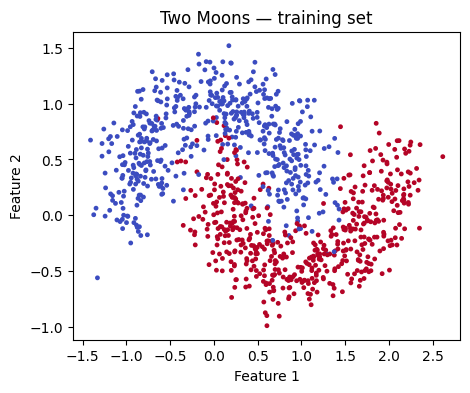

In [2]:
X, y = make_moons(n_samples=1400, noise=0.22, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

X_train_t = torch.tensor(X_train, dtype=torch.float32, device=device)
y_train_t = torch.tensor(y_train, dtype=torch.float32, device=device).view(-1, 1)
X_test_t = torch.tensor(X_test, dtype=torch.float32, device=device)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=12, cmap="coolwarm", edgecolors="none")
ax.set_title("Two Moons — training set")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
plt.show()

## 1.2 The artificial neuron

For an input vector \(x\), an artificial neuron first computes an affine transformation:

\[
a = w^T x + b
\]

It then applies an activation function:

\[
h = f(a)
\]

- **Weights** determine how strongly each input feature contributes.
- **Bias** shifts the response.
- **Activation** transforms the weighted sum.

Common activation functions include:

- **ReLU:** \(f(a)=max(0,a)\), commonly used in hidden layers.
- **Sigmoid:** maps a real value to (0, 1), useful for probability-like outputs.
- **Tanh:** maps a real value to (−1, 1).

A key point: stacking linear layers without nonlinear activations still produces one overall linear transformation. Depth alone does not create nonlinear decision boundaries.

In [3]:
class LinearClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(2, 1)

    def forward(self, x):
        return self.linear(x)  # logits


class MLPClassifier(nn.Module):
    def __init__(self, hidden_width=24):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, hidden_width),
            nn.ReLU(),
            nn.Linear(hidden_width, hidden_width),
            nn.ReLU(),
            nn.Linear(hidden_width, 1)
        )

    def forward(self, x):
        return self.network(x)  # logits


def train_binary_classifier(model, epochs=400, learning_rate=0.025):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.BCEWithLogitsLoss()
    losses = []

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits = model(X_train_t)
        loss = criterion(logits, y_train_t)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    return model, losses


linear_model, linear_losses = train_binary_classifier(LinearClassifier())
mlp_model, mlp_losses = train_binary_classifier(MLPClassifier())

def evaluate_classifier(model):
    model.eval()
    with torch.no_grad():
        probabilities = torch.sigmoid(model(X_test_t)).cpu().numpy().ravel()
    predictions = (probabilities >= 0.5).astype(int)
    return accuracy_score(y_test, predictions)

print(f"Linear classifier test accuracy: {evaluate_classifier(linear_model):.3f}")
print(f"MLP test accuracy:               {evaluate_classifier(mlp_model):.3f}")

Linear classifier test accuracy: 0.866
MLP test accuracy:               0.946


## 1.3 Training a neural network

The training loop has four essential steps:

1. **Forward pass:** compute the model output from the current parameters.
2. **Loss evaluation:** quantify the mismatch between predictions and targets.
3. **Backpropagation:** compute gradients of the loss with respect to model parameters using the chain rule.
4. **Parameter update:** the optimizer uses those gradients to update weights and biases.

For binary classification, `BCEWithLogitsLoss` combines a sigmoid operation with binary cross-entropy in a numerically stable way. Therefore, the model returns logits rather than applying Sigmoid in its final layer.

The optimizer used here is Adam. The learning rate controls the size of parameter updates.

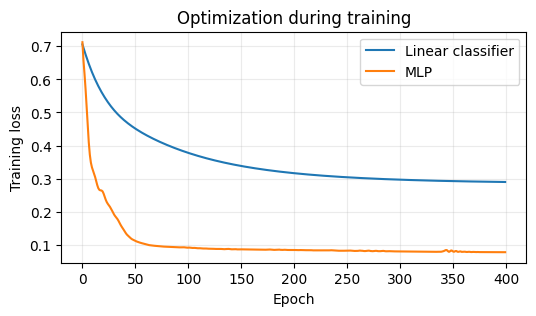

In [4]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(linear_losses, label="Linear classifier")
ax.plot(mlp_losses, label="MLP")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training loss")
ax.set_title("Optimization during training")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 1.4 Inspecting decision boundaries

Accuracy gives one summary number, but it does not show *how* the model separates the data. We therefore visualize the predicted class over a grid of input coordinates.

Interpret the plots carefully:
- A straight boundary is expected from the linear classifier.
- The MLP can form a curved boundary because of its nonlinear hidden layers.
- A more flexible boundary is not automatically better in every dataset; flexibility must be judged against generalization and the data structure.

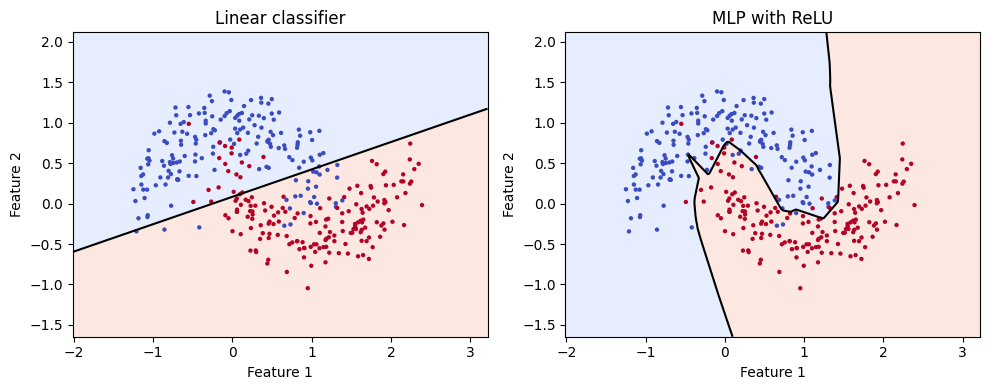

In [5]:
def plot_decision_boundary(model, ax, title):
    x_min, x_max = X[:, 0].min() - 0.6, X[:, 0].max() + 0.6
    y_min, y_max = X[:, 1].min() - 0.6, X[:, 1].max() + 0.6
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 260),
        np.linspace(y_min, y_max, 260)
    )
    grid = torch.tensor(
        np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32, device=device
    )
    model.eval()
    with torch.no_grad():
        scores = torch.sigmoid(model(grid)).cpu().numpy().reshape(xx.shape)

    ax.contourf(xx, yy, scores, levels=[0, 0.5, 1], alpha=0.22, cmap="coolwarm")
    ax.contour(xx, yy, scores, levels=[0.5], colors="black", linewidths=1.5)
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=10, cmap="coolwarm", edgecolors="none")
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_decision_boundary(linear_model, axes[0], "Linear classifier")
plot_decision_boundary(mlp_model, axes[1], "MLP with ReLU")
plt.tight_layout()
plt.show()

### Experiment 1 — Discussion

1. Why is a single linear boundary unable to separate the two moons perfectly?
2. What role do the ReLU layers play?
3. If all ReLU activations were removed, what kind of function would the network represent?
4. Why should we inspect both training loss and test accuracy?

**Key connection:** Neural networks learn a representation through a sequence of parameterized transformations. Nonlinear activations make the learned representation more flexible than a single linear map.
### References
- [PyTorch `nn.Module` — building neural network modules](https://pytorch.org/docs/stable/generated/torch.nn.Module.html)
- [PyTorch `BCEWithLogitsLoss` — binary classification objective](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)
- [PyTorch Autograd — automatic differentiation](https://pytorch.org/docs/stable/autograd.html)
- [PyTorch Optimizers — parameter updates](https://pytorch.org/docs/stable/optim.html)


# Experiment 2 — Building a Basic Autoencoder

## 2.1 From prediction to representation learning

In supervised classification, a model learns a mapping from inputs to labels. An **autoencoder** instead learns to reconstruct its input.

It consists of three conceptual components:

$$
x \xrightarrow{\text{Encoder}} z
\xrightarrow{\text{Decoder}} \hat{x}
$$

- **Encoder:** maps the input to a latent representation.
- **Latent code:** a compact representation of the input.
- **Decoder:** maps the latent code back to the input space.

The model is trained so that the reconstruction $\hat{x}$ is close to the original input \(x\). In this experiment, we do not use class labels for training.

## 2.2 Dataset A — handwritten Digits

We begin with the small Digits dataset available directly through scikit-learn. Each observation is an 8×8 grayscale image, represented as a 64-dimensional vector.

This dataset is intentionally small:
- it keeps training fast during a live session;
- its compact size makes the encoder/decoder architecture easy to inspect;
- it provides a controlled setting for the PCA comparison in Experiment 3.

Pixel values are scaled to [0, 1].

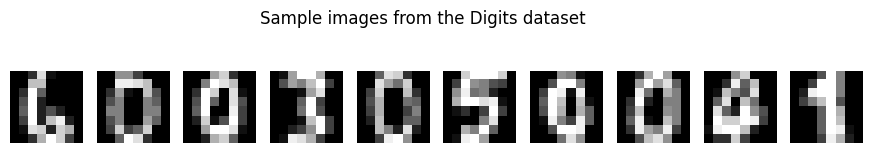

Training samples: 1437
Input dimension: 64


In [6]:
digits = load_digits()
X_digits = digits.images.astype("float32") / 16.0
X_digits = X_digits.reshape(-1, 64)

X_digits_train, X_digits_test = train_test_split(
    X_digits, test_size=0.20, random_state=SEED
)

digits_train_loader = DataLoader(
    TensorDataset(torch.tensor(X_digits_train, dtype=torch.float32)),
    batch_size=128, shuffle=True
)
digits_test_t = torch.tensor(X_digits_test, dtype=torch.float32, device=device)

fig, axes = plt.subplots(1, 10, figsize=(11, 2))
for ax, image in zip(axes, X_digits_train[:10]):
    ax.imshow(image.reshape(8, 8), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Sample images from the Digits dataset")
plt.show()

print("Training samples:", len(X_digits_train))
print("Input dimension:", X_digits_train.shape[1])

## 2.3 Architecture and reconstruction objective

For an input dimension of 64, we use a small fully connected architecture:

$$
64 \longrightarrow 32 \longrightarrow k \longrightarrow 32 \longrightarrow 64
$$

The latent dimension \(k\) is the bottleneck size. We will begin with \(k=16\).

For normalized real-valued image data, we use Mean Squared Error (MSE):

$$
\mathcal{L}_{\mathrm{MSE}}
= \frac{1}{Nd}\sum_{i=1}^{N}\left\lVert x_i-\hat{x}_i\right\rVert_2^2
$$

The encoder and decoder are trained jointly. The final Sigmoid constrains reconstructed pixel values to [0, 1].

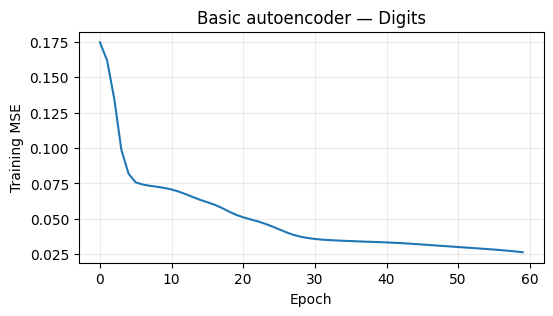

In [7]:
class FullyConnectedAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=16, hidden_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z


def train_autoencoder(model, loader, epochs=50, learning_rate=1e-3,
                      noise_std=0.0, latent_l1=0.0):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    for epoch in range(epochs):
        model.train()
        total_loss, total_items = 0.0, 0

        for (clean_batch,) in loader:
            clean_batch = clean_batch.to(device)

            if noise_std > 0:
                model_input = torch.clamp(
                    clean_batch + noise_std * torch.randn_like(clean_batch), 0, 1
                )
            else:
                model_input = clean_batch

            optimizer.zero_grad()
            reconstruction, latent = model(model_input)

            reconstruction_loss = F.mse_loss(reconstruction, clean_batch)
            sparsity_penalty = latent_l1 * latent.abs().mean()
            loss = reconstruction_loss + sparsity_penalty

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(clean_batch)
            total_items += len(clean_batch)

        history.append(total_loss / total_items)

    return model, history


DIGITS_LATENT_DIM = 16
digits_ae = FullyConnectedAutoencoder(input_dim=64, latent_dim=DIGITS_LATENT_DIM)
digits_ae, digits_ae_history = train_autoencoder(
    digits_ae, digits_train_loader, epochs=60, learning_rate=1e-3
)

plt.figure(figsize=(6, 3))
plt.plot(digits_ae_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Basic autoencoder — Digits")
plt.grid(alpha=0.25)
plt.show()

## 2.4 Reconstruction and latent-space inspection

A decreasing training loss indicates that the model is improving its reconstruction on the training data. We also inspect held-out test examples to see what information is preserved.

The bottleneck introduces a compression constraint:
- a smaller latent dimension forces the model to represent the input with fewer numbers;
- a larger latent dimension gives the model more capacity to preserve details;
- reconstruction quality is only one criterion for judging a representation.

Digits test reconstruction MSE: 0.026503
Latent representation shape: (360, 16)


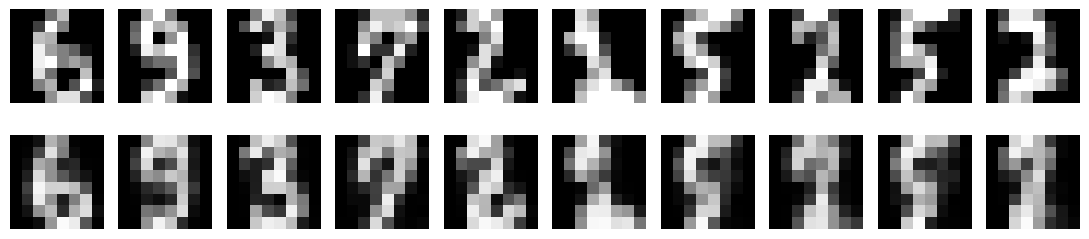

In [8]:
digits_ae.eval()
with torch.no_grad():
    digits_reconstruction, digits_latent = digits_ae(digits_test_t)

digits_test_mse = F.mse_loss(digits_reconstruction, digits_test_t).item()
print(f"Digits test reconstruction MSE: {digits_test_mse:.6f}")
print("Latent representation shape:", tuple(digits_latent.shape))

n_show = 10
fig, axes = plt.subplots(2, n_show, figsize=(11, 3))
for i in range(n_show):
    axes[0, i].imshow(digits_test_t[i].cpu().numpy().reshape(8, 8), cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(digits_reconstruction[i].cpu().numpy().reshape(8, 8), cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.tight_layout()
plt.show()

### Experiment 2 — Discussion

1. Why is the input also the reconstruction target?
2. What is the role of the bottleneck?
3. What might happen if the latent dimension is reduced from 16 to 2?
4. Does a low reconstruction error guarantee that the latent code is useful for classification?

**Optional mini-investigation:** Train the same architecture with latent dimensions 2, 8, and 32. Compare test MSE and reconstructed images. Keep the train/test split fixed.
### References
- [scikit-learn `load_digits` dataset documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)
- [PyTorch `nn.Module` documentation](https://pytorch.org/docs/stable/generated/torch.nn.Module.html)
- Hinton, G. E., & Salakhutdinov, R. R. (2006). *Reducing the Dimensionality of Data with Neural Networks*. Science, 313(5786), 504–507. [https://doi.org/10.1126/science.1127647](https://doi.org/10.1126/science.1127647)


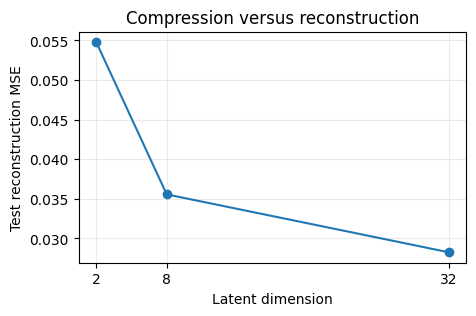

In [9]:
# Optional mini-investigation: compare latent dimensions on the Digits dataset.
latent_dimensions = [2, 8, 32]
dimension_results = []

for k in latent_dimensions:
    model = FullyConnectedAutoencoder(input_dim=64, latent_dim=k)
    model, _ = train_autoencoder(
        model, digits_train_loader, epochs=45, learning_rate=1e-3
    )
    model.eval()
    with torch.no_grad():
        reconstruction, _ = model(digits_test_t)
    mse = F.mse_loss(reconstruction, digits_test_t).item()
    dimension_results.append(mse)

plt.figure(figsize=(5, 3))
plt.plot(latent_dimensions, dimension_results, marker="o")
plt.xticks(latent_dimensions)
plt.xlabel("Latent dimension")
plt.ylabel("Test reconstruction MSE")
plt.title("Compression versus reconstruction")
plt.grid(alpha=0.25)
plt.show()

# Experiment 3 — PCA versus Linear Autoencoder

## 3.1 Why make this comparison?

PCA and a linear autoencoder both learn low-dimensional representations, but they do so differently:

- **PCA** computes a principal subspace using a matrix factorization / eigendecomposition approach.
- **Linear autoencoder** learns encoder and decoder parameters by minimizing reconstruction loss with gradient-based optimization.

Under standard conditions, a linear autoencoder with a bottleneck and squared reconstruction loss can recover the principal subspace. However, its learned weights do not have to be identical to the PCA basis vectors.

## 3.2 Fair comparison protocol

To make the comparison meaningful, we keep the following fixed:

- the same Digits train/test split;
- the same input representation (64-dimensional flattened images);
- the same latent dimension;
- the same reconstruction metric (test MSE).

PCA is applied to centered training data. For the linear autoencoder, we also center the training and test data using the training-set mean. The mean is added back after reconstruction.

This centering step matters because PCA is defined around the data mean.

In [10]:
# PCA baseline
pca = PCA(n_components=DIGITS_LATENT_DIM)
pca.fit(X_digits_train)

pca_reconstruction = pca.inverse_transform(
    pca.transform(X_digits_test)
)
pca_test_mse = np.mean((X_digits_test - pca_reconstruction) ** 2)

# Linear autoencoder
class LinearAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim):
        super().__init__()
        self.encoder = nn.Linear(input_dim, latent_dim, bias=False)
        self.decoder = nn.Linear(latent_dim, input_dim, bias=False)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

digits_mean = X_digits_train.mean(axis=0, keepdims=True)
X_digits_train_centered = X_digits_train - digits_mean
X_digits_test_centered = X_digits_test - digits_mean

centered_loader = DataLoader(
    TensorDataset(torch.tensor(X_digits_train_centered, dtype=torch.float32)),
    batch_size=128, shuffle=True
)
centered_test_t = torch.tensor(
    X_digits_test_centered, dtype=torch.float32, device=device
)

linear_ae = LinearAutoencoder(input_dim=64, latent_dim=DIGITS_LATENT_DIM)
linear_ae, linear_ae_history = train_autoencoder(
    linear_ae, centered_loader, epochs=180, learning_rate=2e-3
)

linear_ae.eval()
with torch.no_grad():
    linear_reconstruction_centered, _ = linear_ae(centered_test_t)

linear_reconstruction = (
    linear_reconstruction_centered.cpu().numpy() + digits_mean
)
linear_ae_test_mse = np.mean((X_digits_test - linear_reconstruction) ** 2)

print(f"PCA test reconstruction MSE:              {pca_test_mse:.6f}")
print(f"Linear autoencoder test reconstruction MSE: {linear_ae_test_mse:.6f}")

PCA test reconstruction MSE:              0.011249
Linear autoencoder test reconstruction MSE: 0.011245


## 3.3 Compare reconstructions and errors

The numerical comparison uses the same test samples and the same MSE definition. We also display one example reconstructed by each method.

Do not expect exact equality between the two numbers in a finite training run. PCA solves its linear subspace problem directly, whereas the autoencoder approaches an optimum through iterative optimization. Initialization, learning rate, number of epochs, and optimization error can affect the result.

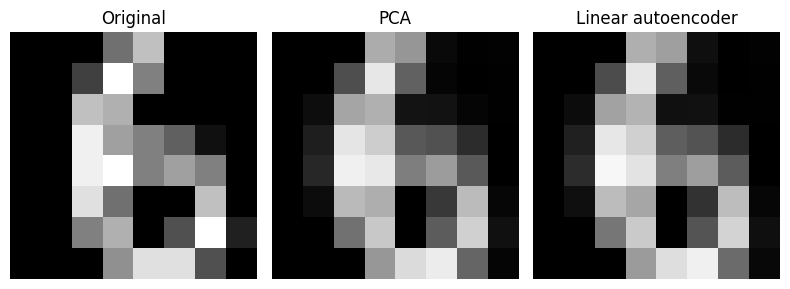

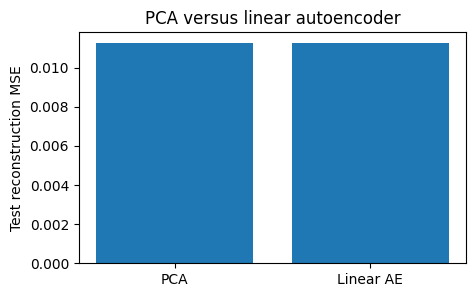

In [11]:
sample_index = 0
fig, axes = plt.subplots(1, 3, figsize=(8, 3))
images = [
    X_digits_test[sample_index].reshape(8, 8),
    pca_reconstruction[sample_index].reshape(8, 8),
    linear_reconstruction[sample_index].reshape(8, 8)
]
titles = ["Original", "PCA", "Linear autoencoder"]
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 3))
plt.bar(["PCA", "Linear AE"], [pca_test_mse, linear_ae_test_mse])
plt.ylabel("Test reconstruction MSE")
plt.title("PCA versus linear autoencoder")
plt.show()

## 3.4 What should we conclude?

- PCA provides a direct solution for the best rank-k linear reconstruction subspace under the standard squared-error setting.
- A linear autoencoder learns a reconstruction map through optimization.
- At an ideal optimum, the two methods can span the same principal subspace.
- Encoder coordinates may differ because different bases can represent the same subspace.
- A small performance gap in this experiment can reflect incomplete optimization rather than a fundamental difference in the ideal solution.

**Discussion:** Why is comparing the encoder weight matrix directly with the PCA component matrix not necessarily a valid test of subspace equivalence?
### References
- [scikit-learn PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- Hinton, G. E., & Salakhutdinov, R. R. (2006). *Reducing the Dimensionality of Data with Neural Networks*. Science, 313(5786), 504–507. [https://doi.org/10.1126/science.1127647](https://doi.org/10.1126/science.1127647)


### Execution status for this delivered copy

Experiments 1–3 and Optional Experiment A were executed in the available CPU runtime; their outputs are saved below the corresponding code cells. The Fashion-MNIST and CIFAR-10 download cells could not be executed in the file-building runtime because external network access was unavailable. Their original code is preserved unchanged. Run those cells in Google Colab to generate the corresponding outputs.

# Experiment 4 — Denoising Autoencoder

## 4.1 From reconstruction to denoising

A basic autoencoder receives a clean sample and is trained to reconstruct that same clean sample. A **denoising autoencoder (DAE)** changes the learning task:

$$
\tilde{x} = x + \epsilon
\qquad\text{and}\qquad
\tilde{x} \longrightarrow \hat{x} \approx x
$$

The input is corrupted, but the target remains clean. The model therefore learns a mapping from corrupted observations toward clean examples.

This is a useful connection to signal processing: the model learns a data-dependent reconstruction rule from examples rather than applying a fixed filter.

## 4.2 Dataset B — Fashion-MNIST

For denoising, we use **Fashion-MNIST**, which contains 28×28 grayscale images from ten clothing categories. Compared with the small Digits images, these samples have more varied shapes and textures.

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 268kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.00MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.65MB/s]


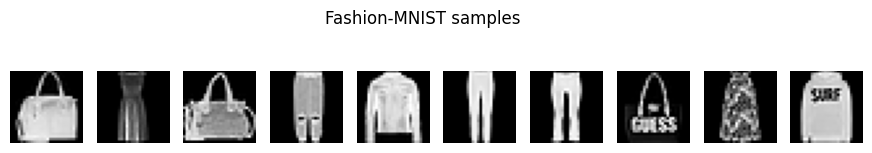

Fashion-MNIST training subset: (12000, 784)
Fashion-MNIST test subset: (2000, 784)


In [12]:
from torchvision.datasets import FashionMNIST
from torchvision import transforms

fashion_train_dataset = FashionMNIST(
    root="./data", train=True, download=True, transform=transforms.ToTensor()
)
fashion_test_dataset = FashionMNIST(
    root="./data", train=False, download=True, transform=transforms.ToTensor()
)

# Fixed, reproducible subsets for the live session.
rng = np.random.default_rng(SEED)
fashion_train_indices = rng.choice(len(fashion_train_dataset), size=12000, replace=False)
fashion_test_indices = rng.choice(len(fashion_test_dataset), size=2000, replace=False)

X_fashion_train = fashion_train_dataset.data[fashion_train_indices].numpy().astype("float32") / 255.0
X_fashion_test = fashion_test_dataset.data[fashion_test_indices].numpy().astype("float32") / 255.0

X_fashion_train = X_fashion_train.reshape(-1, 784)
X_fashion_test = X_fashion_test.reshape(-1, 784)

fashion_train_loader = DataLoader(
    TensorDataset(torch.tensor(X_fashion_train, dtype=torch.float32)),
    batch_size=128, shuffle=True
)
fashion_test_t = torch.tensor(X_fashion_test, dtype=torch.float32, device=device)

fig, axes = plt.subplots(1, 10, figsize=(11, 2))
for ax, image in zip(axes, X_fashion_train[:10]):
    ax.imshow(image.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Fashion-MNIST samples")
plt.show()

print("Fashion-MNIST training subset:", X_fashion_train.shape)
print("Fashion-MNIST test subset:", X_fashion_test.shape)

## 4.3 Corruption model and training objective

We add Gaussian noise to the clean training images and clip the result to the valid pixel range:

$$
\tilde{x} = \operatorname{clip}(x + \epsilon, 0, 1),
\qquad \epsilon \sim \mathcal{N}(0,\sigma^2 I)
$$

The network receives \(\tilde{x}\), but the loss is computed against the original clean image \(x\).

This distinction is essential:
- **Input:** noisy image;
- **Target:** clean image;
- **Objective:** minimize reconstruction error between the output and the clean target.

The noise level \(\sigma\) controls the corruption strength. If it is too small, the task may be trivial; if it is too large, important information may be destroyed.

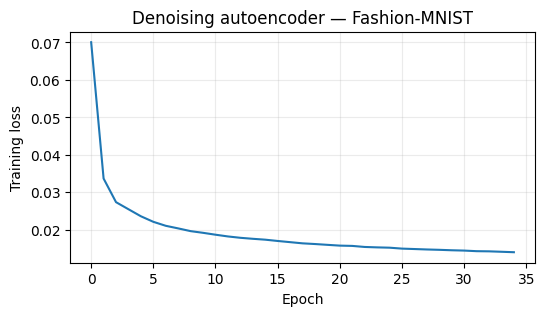

In [13]:
FASHION_LATENT_DIM = 64
FASHION_NOISE_STD = 0.35

fashion_ae = FullyConnectedAutoencoder(
    input_dim=784, latent_dim=FASHION_LATENT_DIM, hidden_dim=256
)
fashion_dae, fashion_dae_history = train_autoencoder(
    fashion_ae,
    fashion_train_loader,
    epochs=35,
    learning_rate=1e-3,
    noise_std=FASHION_NOISE_STD
)

plt.figure(figsize=(6, 3))
plt.plot(fashion_dae_history)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Denoising autoencoder — Fashion-MNIST")
plt.grid(alpha=0.25)
plt.show()

## 4.4 Evaluate on a fixed noisy test set

We create one fixed noisy test set so that the comparison is repeatable. We report:

1. MSE between the noisy input and clean target;
2. MSE between the denoised output and clean target.

A lower output MSE indicates that the model improved reconstruction for this particular corruption setting. It does not prove that the model can remove every kind of noise or artifact.

In [14]:
torch.manual_seed(SEED + 10)
fashion_noisy_test = torch.clamp(
    fashion_test_t + FASHION_NOISE_STD * torch.randn_like(fashion_test_t),
    0, 1
)

fashion_dae.eval()
with torch.no_grad():
    fashion_denoised, fashion_latent = fashion_dae(fashion_noisy_test)

fashion_noisy_mse = F.mse_loss(fashion_noisy_test, fashion_test_t).item()
fashion_denoised_mse = F.mse_loss(fashion_denoised, fashion_test_t).item()

print(f"Noisy input MSE:     {fashion_noisy_mse:.6f}")
print(f"Denoised output MSE: {fashion_denoised_mse:.6f}")

Noisy input MSE:     0.068339
Denoised output MSE: 0.014334


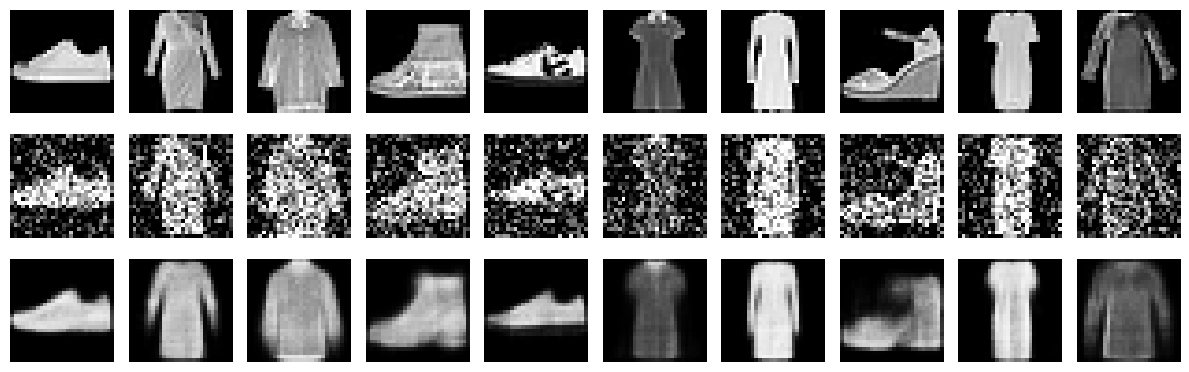

In [15]:
n_show = 10
fig, axes = plt.subplots(3, n_show, figsize=(12, 4))
rows = [
    (fashion_test_t[:n_show].cpu().numpy(), "Clean target"),
    (fashion_noisy_test[:n_show].cpu().numpy(), "Noisy input"),
    (fashion_denoised[:n_show].cpu().numpy(), "Denoised output")
]
for row_index, (images, row_label) in enumerate(rows):
    for col_index in range(n_show):
        axes[row_index, col_index].imshow(
            images[col_index].reshape(28, 28), cmap="gray", vmin=0, vmax=1
        )
        axes[row_index, col_index].axis("off")
    axes[row_index, 0].set_ylabel(row_label, rotation=0, labelpad=58, va="center")
plt.tight_layout()
plt.show()

## 4.5 Interpretation and limitations

The denoising autoencoder does not know the original clean image at test time. It has learned statistical regularities from the training examples and uses them to produce a plausible reconstruction.

Important limitations:
- performance depends on the training corruption model;
- Gaussian-noise training does not guarantee robustness to blur, missing pixels, compression artifacts, or structured interference;
- denoising can remove fine details along with noise;
- the model may produce a plausible image rather than recover the exact original signal.

**Discussion questions**
1. Why is the clean image used as the target?
2. What changes if we increase the noise standard deviation?
3. Would a model trained on Gaussian noise necessarily handle salt-and-pepper noise?
4. How would you adapt this experiment for one-dimensional audio signals?
### References
- [torchvision FashionMNIST dataset documentation](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html)
- Vincent, P., Larochelle, H., Bengio, Y., & Manzagol, P.-A. (2008). *Extracting and Composing Robust Features with Denoising Autoencoders*. Proceedings of ICML. [https://doi.org/10.1145/1390156.1390294](https://doi.org/10.1145/1390156.1390294)


# Optional Experiment A — Sparse Autoencoder

## A.1 Adding a sparsity constraint to the latent representation

Week 5 introduced sparse representations as a way to describe observations using a small number of active coefficients. A sparse autoencoder brings a related idea into a learned nonlinear representation.

We add an L1 penalty to the latent activations:

$$
\mathcal{L}_{total}
=
\mathcal{L}_{reconstruction}
+
\lambda\,\frac{1}{N}\sum_i \|z_i\|_1
$$

This penalty encourages latent activations to be small and can promote near-zero values. It is important to distinguish **sparse activations** from **sparse weights**: the penalty below is applied to the latent code, not to the model parameters.

In [16]:
SPARSE_LAMBDA = 2e-3
sparse_digits_ae = FullyConnectedAutoencoder(input_dim=64, latent_dim=16)
sparse_digits_ae, sparse_history = train_autoencoder(
    sparse_digits_ae,
    digits_train_loader,
    epochs=60,
    learning_rate=1e-3,
    latent_l1=SPARSE_LAMBDA
)

sparse_digits_ae.eval()
with torch.no_grad():
    sparse_reconstruction, sparse_latent = sparse_digits_ae(digits_test_t)

sparse_test_mse = F.mse_loss(sparse_reconstruction, digits_test_t).item()
near_zero_fraction = (sparse_latent.abs() < 0.05).float().mean().item()

print(f"Basic AE test MSE:  {digits_test_mse:.6f}")
print(f"Sparse AE test MSE: {sparse_test_mse:.6f}")
print(f"Fraction of |z| < 0.05: {near_zero_fraction:.3f}")

Basic AE test MSE:  0.026503
Sparse AE test MSE: 0.023336
Fraction of |z| < 0.05: 0.030


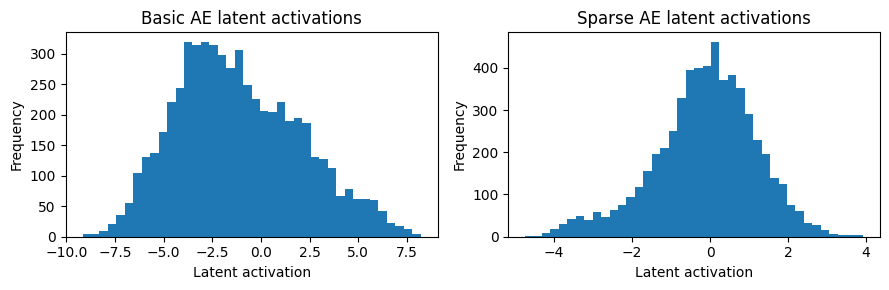

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(digits_latent.detach().cpu().numpy().ravel(), bins=40)
axes[0].set_title("Basic AE latent activations")
axes[1].hist(sparse_latent.detach().cpu().numpy().ravel(), bins=40)
axes[1].set_title("Sparse AE latent activations")
for ax in axes:
    ax.set_xlabel("Latent activation")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

### Optional discussion

- Does the L1 penalty increase the fraction of near-zero latent activations?
- What happens to reconstruction MSE as the penalty becomes stronger?
- How is this learned sparse code related to the sparse representation idea from Week 5?
- Why is sparsity a trade-off rather than a free improvement?

Try `SPARSE_LAMBDA` values such as 0, 0.0005, 0.002, and 0.01. Keep the architecture and data split fixed.
### References
- [PyTorch `torch.nn` documentation](https://pytorch.org/docs/stable/nn.html)
- Ng, A. (2011). *Sparse Autoencoder*. CS294A lecture notes. [https://web.stanford.edu/class/cs294a/sparseAutoencoder.pdf](https://web.stanford.edu/class/cs294a/sparseAutoencoder.pdf)


# Optional Experiment B — CIFAR-10 and a Convolutional Autoencoder

This extension is intentionally optional. CIFAR-10 contains 32×32 RGB images and is more demanding than the grayscale datasets used in the live session. It motivates a different architecture: a **convolutional autoencoder**.

Unlike a fully connected model that flattens all pixels, convolutional layers exploit local spatial structure and share filters across image locations. This is often a more natural choice for images.

The optional section is not required for the main learning objectives. Run it only when time and compute resources permit.

100%|██████████| 170M/170M [19:48<00:00, 143kB/s]


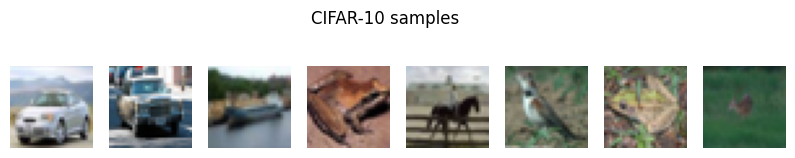

In [18]:
from torchvision.datasets import CIFAR10

cifar_transform = transforms.ToTensor()
cifar_train_dataset = CIFAR10(
    root="./data", train=True, download=True, transform=cifar_transform
)

# Small subset to keep this extension manageable.
cifar_indices = np.random.default_rng(SEED).choice(
    len(cifar_train_dataset), size=4000, replace=False
)
cifar_images = torch.stack([cifar_train_dataset[i][0] for i in cifar_indices])

cifar_loader = DataLoader(
    TensorDataset(cifar_images), batch_size=64, shuffle=True
)

fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for ax, image in zip(axes, cifar_images[:8]):
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.axis("off")
plt.suptitle("CIFAR-10 samples")
plt.show()

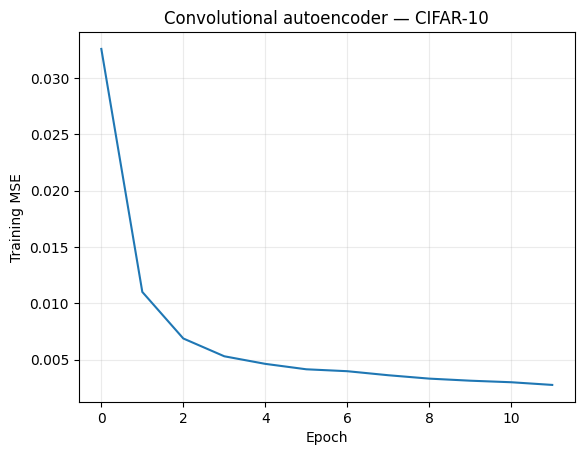

In [19]:
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


conv_ae = ConvAutoencoder().to(device)
optimizer = torch.optim.Adam(conv_ae.parameters(), lr=1e-3)
cifar_history = []

for epoch in range(12):
    conv_ae.train()
    total_loss, total_items = 0.0, 0
    for (batch,) in cifar_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        reconstruction, _ = conv_ae(batch)
        loss = F.mse_loss(reconstruction, batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(batch)
        total_items += len(batch)
    cifar_history.append(total_loss / total_items)

plt.plot(cifar_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Convolutional autoencoder — CIFAR-10")
plt.grid(alpha=0.25)
plt.show()

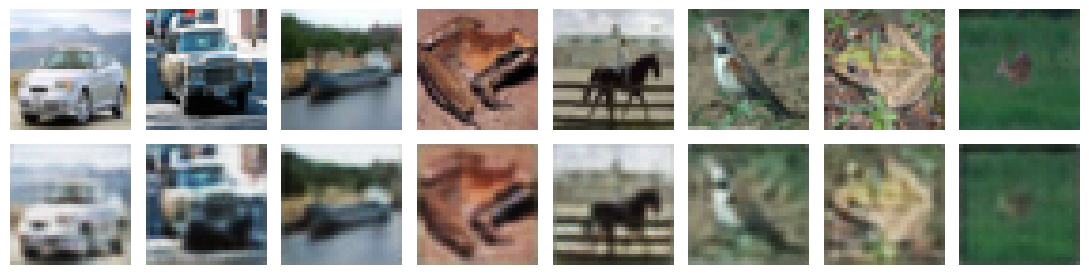

In [20]:
conv_ae.eval()
with torch.no_grad():
    sample_batch = cifar_images[:8].to(device)
    cifar_reconstruction, _ = conv_ae(sample_batch)

fig, axes = plt.subplots(2, 8, figsize=(11, 3))
for i in range(8):
    axes[0, i].imshow(sample_batch[i].cpu().permute(1, 2, 0).numpy())
    axes[1, i].imshow(cifar_reconstruction[i].cpu().permute(1, 2, 0).numpy())
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.tight_layout()
plt.show()

### Optional CIFAR-10 discussion

1. Why are convolutional layers a natural choice for images?
2. What spatial information might be harder to preserve after downsampling?
3. How does the convolutional architecture differ from the fully connected architecture used for Digits and Fashion-MNIST?
4. What changes would be needed to turn this model into a denoising convolutional autoencoder?
### References
- [torchvision CIFAR10 dataset documentation](https://pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html)
- [PyTorch Convolutional Layers documentation](https://pytorch.org/docs/stable/nn.html#convolution-layers)


# Final Synthesis

## Summary of the methods

| Method | Representation / objective | Main idea |
|---|---|---|
| Linear classifier | Affine decision function | One linear decision boundary |
| MLP | Learned nonlinear mapping | Hidden layers and nonlinear activations |
| PCA | Principal subspace | Linear low-dimensional representation |
| Basic autoencoder | Reconstruction through a bottleneck | Learn a compact code |
| Linear autoencoder | Linear reconstruction through a bottleneck | Optimization-based route to a principal subspace |
| Denoising autoencoder | Corrupted input, clean target | Learn data-dependent denoising |
| Sparse autoencoder | Reconstruction plus latent L1 penalty | Encourage sparse latent activations |
| Convolutional autoencoder | Spatially structured encoding and decoding | Exploit local image structure |

## Connections to earlier weeks

- **Week 4 — PCA / SVD:** the linear autoencoder comparison connects learned reconstruction to principal subspaces.
- **Week 5 — Sparsity:** the sparse autoencoder adds an L1 penalty to learned latent activations.
- **Signal processing perspective:** denoising is a reconstruction problem whose behavior depends on the assumed corruption process and the data distribution.

## Exit questions

1. Why are nonlinear activations important in an MLP?
2. What is the role of the bottleneck in an autoencoder?
3. Under what conditions is a linear autoencoder related to PCA?
4. How do the input and target differ in a denoising autoencoder?
5. What does the L1 penalty encourage in a sparse autoencoder?
6. Why might a convolutional autoencoder be preferable for CIFAR-10?

# References and Further Reading

The following sources support the implementations and concepts used in this session. Links point to official documentation or original research publications.

## Neural Networks and PyTorch
- PyTorch. [Neural network package (`torch.nn`)](https://pytorch.org/docs/stable/nn.html).
- PyTorch. [Autograd: automatic differentiation](https://pytorch.org/docs/stable/autograd.html).
- PyTorch. [Optimization package (`torch.optim`)](https://pytorch.org/docs/stable/optim.html).
- PyTorch. [Binary cross-entropy with logits](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html).

## Autoencoders and Representation Learning
- Hinton, G. E., & Salakhutdinov, R. R. (2006). *Reducing the Dimensionality of Data with Neural Networks*. Science, 313(5786), 504–507. [https://doi.org/10.1126/science.1127647](https://doi.org/10.1126/science.1127647).
- Vincent, P., Larochelle, H., Bengio, Y., & Manzagol, P.-A. (2008). *Extracting and Composing Robust Features with Denoising Autoencoders*. Proceedings of ICML. [https://doi.org/10.1145/1390156.1390294](https://doi.org/10.1145/1390156.1390294).
- Ng, A. (2011). *Sparse Autoencoder*. CS294A lecture notes. [https://web.stanford.edu/class/cs294a/sparseAutoencoder.pdf](https://web.stanford.edu/class/cs294a/sparseAutoencoder.pdf).

## Datasets and Classical Baselines
- scikit-learn. [The handwritten digits dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).
- scikit-learn. [Principal Component Analysis (PCA)](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).
- torchvision. [Fashion-MNIST dataset](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html).
- torchvision. [CIFAR-10 dataset](https://pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html).

## Implementation note
The notebook uses PyTorch for model definitions, automatic differentiation, loss functions, and optimization; scikit-learn for Digits and PCA; and torchvision for Fashion-MNIST and the optional CIFAR-10 extension.
